# Task 0: Colab environment and baseline render

Connect this notebook to a Google Colab GPU runtime in VS Code (or choose **Runtime → Change runtime type → GPU** in Colab), then run the notebook from top to bottom. The first cell clones or fast-forwards the homework repository from GitHub, so commit and push local changes to the repository before rerunning it in Colab. The notebook checks the CUDA runtime and compiler, installs project dependencies and builds the rasterizer, then renders and packages the starter output. The build may take several minutes.

If the GPU or `nvcc` check fails, stop and select a GPU runtime; do not continue with a CPU runtime.

In [ ]:
import os
import pathlib
import subprocess

repo_url = 'https://github.com/jon-of-us/gaussian-splatting-homwork.git'
assignment_root = pathlib.Path('/content/hw1_2026_student')
if (assignment_root / '.git').is_dir():
    subprocess.run(['git', '-C', str(assignment_root), 'pull', '--ff-only'], check=True)
elif assignment_root.exists():
    raise FileExistsError(
        f'{assignment_root} exists but is not a Git checkout. Rename or remove that folder in Colab, then rerun this cell.'
    )
else:
    subprocess.run(['git', 'clone', '--depth', '1', repo_url, str(assignment_root)], check=True)

if not (assignment_root / 'render.py').is_file() or not (assignment_root / 'scripts/setup_environment.sh').is_file():
    raise FileNotFoundError(f'Homework repository is missing required files: {assignment_root}')
os.chdir(assignment_root)
print(f'Assignment directory: {pathlib.Path.cwd()}')

Assignment directory: /content/hw1_2026_student


In [4]:
import torch
import torch.utils.cpp_extension
import torchvision

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Select a GPU under Runtime → Change runtime type, then rerun this notebook.')
if torch.utils.cpp_extension.CUDA_HOME is None:
    raise RuntimeError('CUDA Toolkit was not found. Select a Colab GPU runtime with nvcc available.')

subprocess.run(['nvidia-smi'], check=True)
subprocess.run(['nvcc', '--version'], check=True)
print(f'Python: {os.sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'torchvision: {torchvision.__version__}')
print(f'PyTorch CUDA: {torch.version.cuda}')
print(f'GPU: {torch.cuda.get_device_name(0)}')

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4


## Fix the rasterizer header

The Colab checkout may not yet contain the local header fix. The next cell adds missing standard headers needed by the CUDA compiler. It modifies the tracked file in the temporary Colab checkout, so start a fresh runtime after pushing the fix rather than pulling over that local modification.

In [5]:
header = assignment_root / 'submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h'
source = header.read_text(encoding='utf-8')
required_includes = ['#include <cstddef>', '#include <cstdint>', '#include <stdint.h>']
missing_includes = [line for line in required_includes if line not in source.splitlines()]
if missing_includes:
    if '#pragma once\n' not in source:
        raise RuntimeError(f'Unexpected header format; did not modify {header}')
    source = source.replace('#pragma once\n', '#pragma once\n\n' + '\n'.join(missing_includes) + '\n', 1)
    header.write_text(source, encoding='utf-8')
    print(f'Added missing headers to {header}')
else:
    print(f'Required headers are already present in {header}')

Required headers are already present in /content/hw1_2026_student/submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h


## Install dependencies and build the CUDA extension

The repository helper uses the notebook kernel's Python and the CUDA-enabled PyTorch already installed in Colab. It checks compatibility, installs `requirements.txt`, runs the runtime interoperability checks, and compiles the rasterization extension. The job limit is set to two to reduce peak memory use. If the build fails, check the compiler output above the traceback. The following diagnostic cell is optional and reruns the setup; skip it when running the notebook normally.

In [6]:
import importlib
import sys

build_env = os.environ.copy()
build_env['MAX_JOBS'] = '2'
build_env['HW1_PYTHON'] = sys.executable
with subprocess.Popen(
    ['bash', 'scripts/setup_environment.sh'],
    env=build_env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
) as build:
    for line in build.stdout:
        print(line, end='', flush=True)
    if build.wait() != 0:
        raise subprocess.CalledProcessError(build.returncode, build.args)

rasterizer_module = importlib.import_module('diff_gaussian_rasterization')
cuda_extension = importlib.import_module('diff_gaussian_rasterization._C')
print(f'Rasterizer: {rasterizer_module.__file__}')
print(f'CUDA extension: {cuda_extension.__file__}')

Active Python: /usr/bin/python3
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0 Toolkit: 13.0
Environment preflight passed; compiler compatibility is checked during the build.
NumPy/Torch conversion, CUDA arithmetic and PNG saving: passed
Active Python: /usr/bin/python3
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0 Toolkit: 13.0
Environment preflight passed; compiler compatibility is checked during the build.
running clean
removing 'build/temp.linux-x86_64-cpython-313' (and everything under it)
removing 'build/lib.linux-x86_64-cpython-313' (and everything under it)
removing 'build/bdist.linux-x86_64' (and everything under it)
'build/scripts-3.13' does not exist -- can't clean it
removing 'build'
Processing ./.
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for diff_gaussian_rasterization: filename=diff_gaussian_rasterization-0.1.0-cp313-cp313-linux_x86_64.whl size=

In [7]:
import os
import subprocess
import sys

build_env = os.environ.copy()
build_env['MAX_JOBS'] = '2'
result = subprocess.run(
[sys.executable, '-m', 'pip', 'install', '-v', '--no-build-isolation', '--no-deps', '--force-reinstall', '.'],
cwd='/content/hw1_2026_student/submodules/diff-gaussian-rasterization',
env=build_env,
stdout=subprocess.PIPE,
stderr=subprocess.STDOUT,
text=True,
)
print(result.stdout)
result.check_returncode()

Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing ./.
  Preparing metadata (pyproject.toml): started
  Running command Preparing metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info
  writing /tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-modern-metadata-ks572le4/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  creating '/t

## Render and preserve the starter baseline

This runs the starter implementation before any TODOs are changed. It copies all five generated views to a separate directory so later runs cannot overwrite the baseline, displays view 0, and downloads a ZIP containing the baseline images and environment details. Extract the archive into the local `report/` directory.

In [8]:
import shutil

subprocess.run([os.sys.executable, 'render.py'], check=True)
render_dir = pathlib.Path('renders')
baseline_dir = pathlib.Path('report/task0_baseline_views')
baseline_dir.mkdir(parents=True, exist_ok=True)

baseline_images = [render_dir / f'{index:05d}.png' for index in range(5)]
missing_images = [str(path) for path in baseline_images if not path.is_file()]
if missing_images:
    raise FileNotFoundError(f'Expected five rendered camera views; missing: {missing_images}')
for image_path in baseline_images:
    shutil.copy2(image_path, baseline_dir / image_path.name)

environment_report = pathlib.Path('report/task0_environment.txt')
environment_report.write_text(
    '\n'.join([
        f'Python: {os.sys.version.split()[0]}',
        f'PyTorch: {torch.__version__}',
        f'torchvision: {torchvision.__version__}',
        f'PyTorch CUDA: {torch.version.cuda}',
        f'GPU: {torch.cuda.get_device_name(0)}',
        f'CUDA Toolkit: {torch.utils.cpp_extension.CUDA_HOME}',
    ]) + '\n',
    encoding='utf-8',
)
print(f'Preserved {len(baseline_images)} baseline images in {baseline_dir}')
print(environment_report.read_text(encoding='utf-8'))

Preserved 5 baseline images in report/task0_baseline_views
Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4
CUDA Toolkit: /usr/local/cuda



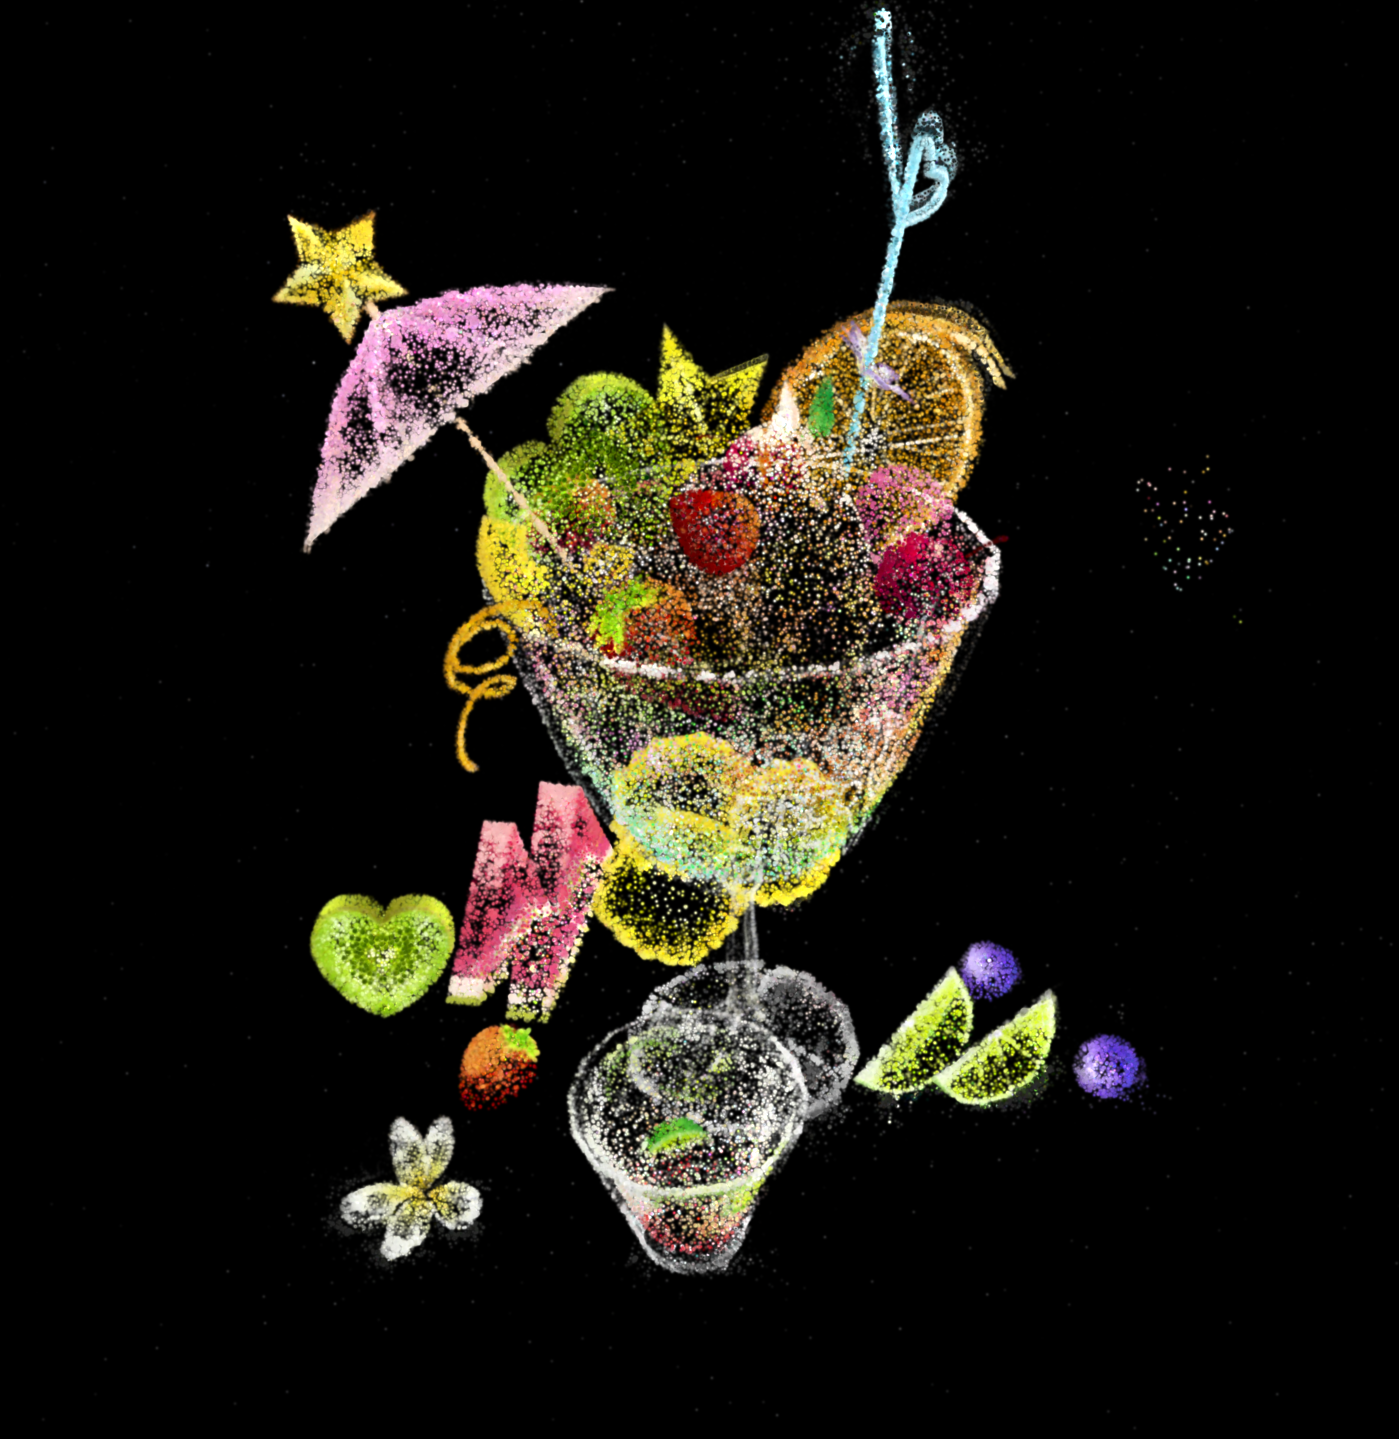

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import google.colab.files
import IPython.display
import zipfile

IPython.display.display(IPython.display.Image(filename=str(baseline_dir / '00000.png')))
archive_path = pathlib.Path('/content/task0_artifacts.zip')
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for image_path in sorted(baseline_dir.glob('*.png')):
        archive.write(image_path, arcname=f'task0_baseline_views/{image_path.name}')
    archive.write(environment_report, arcname='task0_environment.txt')
google.colab.files.download(str(archive_path))